# Parte Específica — Análise Exploratória (Titanic)

Dataset: [DT Titanic Dataset (Kaggle)](https://www.kaggle.com/datasets/qurat01/dt-titanic-dataset) — 891 passageiros, 12 colunas.

Problema: **classificação** (variável alvo `Survived`).

> ✍️ **Análise do grupo:** _(preencher)_

**Pergunta de pesquisa:** _(definir)_

**Público-alvo:** _(definir)_

In [1]:
# [IA] Claude – configuração do notebook e imports
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.parte_especifica import dados as dd

OUT = RAIZ / "out" / "parte_especifica" / "eda"
OUT.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

def salvar(fig, nome):
    fig.savefig(OUT / nome, dpi=150, bbox_inches="tight")

bruto = dd.carregar_bruto()
df = dd.adicionar_derivadas(bruto)
bruto.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.050,NaN,S


## 1. Estrutural

### Dicionário das variáveis

| Coluna | Significado | Tipo |
|---|---|---|
| PassengerId | Identificador do passageiro | identificador |
| Survived | Sobreviveu (1) ou não (0) — **alvo** | qualitativa nominal (binária) |
| Pclass | Classe do bilhete (1ª, 2ª, 3ª) | qualitativa ordinal |
| Name | Nome do passageiro | texto |
| Sex | Sexo | qualitativa nominal |
| Age | Idade (anos) | quantitativa contínua |
| SibSp | Nº de irmãos/cônjuges a bordo | quantitativa discreta |
| Parch | Nº de pais/filhos a bordo | quantitativa discreta |
| Ticket | Código do bilhete | texto |
| Fare | Tarifa paga | quantitativa contínua |
| Cabin | Código da cabine | texto |
| Embarked | Porto de embarque (C = Cherbourg, Q = Queenstown, S = Southampton) | qualitativa nominal |

### Variáveis derivadas (criadas em `src/parte_especifica/dados.py`)

| Coluna | Como é obtida |
|---|---|
| Title | Pronome de tratamento extraído de `Name` (Mr, Mrs, Miss, Master, Raro) |
| FamilySize | `SibSp + Parch + 1` |
| Deck | Primeira letra de `Cabin` ("Desconhecido" se ausente) |
| Cabin_known | 1 se `Cabin` está preenchida |
| Age_missing | 1 se `Age` estava faltando no dado original |
| TicketGroupSize | Nº de passageiros com o mesmo `Ticket` |

In [2]:
# [IA] Claude – dimensões, tipos e valores únicos
print(f"Linhas: {bruto.shape[0]} | Colunas originais: {bruto.shape[1]}")
pd.DataFrame({
    "dtype": bruto.dtypes.astype(str),
    "valores_unicos": bruto.nunique(),
    "faltantes": bruto.isna().sum(),
    "% faltantes": (bruto.isna().mean() * 100).round(1),
    "exemplo": bruto.iloc[0],
})

Linhas: 891 | Colunas originais: 12


,dtype,valores_unicos,faltantes,% faltantes,exemplo
PassengerId,int64,891,0,0.0,1
Survived,int64,2,0,0.0,0
Pclass,int64,3,0,0.0,3
Name,str,891,0,0.0,"Braund, Mr. Owen Harris"
Sex,str,2,0,0.0,male
Age,float64,88,177,19.9,22.0
SibSp,int64,7,0,0.0,1
Parch,int64,7,0,0.0,0
Ticket,str,681,0,0.0,A/5 21171
Fare,float64,248,0,0.0,7.25


In [3]:
# [IA] Claude – checagens de consistência
print("Linhas duplicadas:", bruto.duplicated().sum())
print("PassengerId duplicados:", bruto["PassengerId"].duplicated().sum())
print("Passageiros com Fare = 0:", (bruto["Fare"] == 0).sum())
idades = bruto["Age"].dropna()
print("Idades não inteiras:", ((idades % 1) != 0).sum(), "| idades < 1:", (idades < 1).sum())
print("Idades terminadas em .5 (estimadas, segundo a documentação do Kaggle):", ((idades % 1) == 0.5).sum())
print("Bilhetes compartilhados por mais de 1 passageiro:", (bruto["Ticket"].value_counts() > 1).sum())
print("\nTítulos encontrados no nome:")
print(bruto["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).value_counts().to_string())

Linhas duplicadas: 0
PassengerId duplicados: 0
Passageiros com Fare = 0: 15
Idades não inteiras: 25 | idades < 1: 7
Idades terminadas em .5 (estimadas, segundo a documentação do Kaggle): 18
Bilhetes compartilhados por mais de 1 passageiro: 134

Títulos encontrados no nome:
Name
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1


In [4]:
# [IA] Claude – passageiros com tarifa zero
bruto[bruto["Fare"] == 0][["PassengerId", "Name", "Pclass", "Ticket", "Fare", "Survived"]]

,PassengerId,Name,Pclass,Ticket,Fare,Survived
179,180,"Leonard, Mr. Lionel",3,LINE,0.0,0
263,264,"Harrison, Mr. William",1,112059,0.0,0
271,272,"Tornquist, Mr. William Henry",3,LINE,0.0,1
277,278,"Parkes, Mr. Francis ""Frank""",2,239853,0.0,0
302,303,"Johnson, Mr. William Cahoone Jr",3,LINE,0.0,0
413,414,"Cunningham, Mr. Alfred Fleming",2,239853,0.0,0
466,467,"Campbell, Mr. William",2,239853,0.0,0
481,482,"Frost, Mr. Anthony Wood ""Archie""",2,239854,0.0,0
597,598,"Johnson, Mr. Alfred",3,LINE,0.0,0
633,634,"Parr, Mr. William Henry Marsh",1,112052,0.0,0


> ✍️ **Análise do grupo:** _(preencher)_

_Tipos das variáveis, inconsistências encontradas e decisões._

## 2. Dados faltantes e mecanismo de ausência

Para discutir o mecanismo (MCAR, MAR ou MNAR), compara-se a taxa de ausência entre grupos de outras variáveis.
Se a ausência varia muito conforme uma variável observada, ela **não** é completamente aleatória.

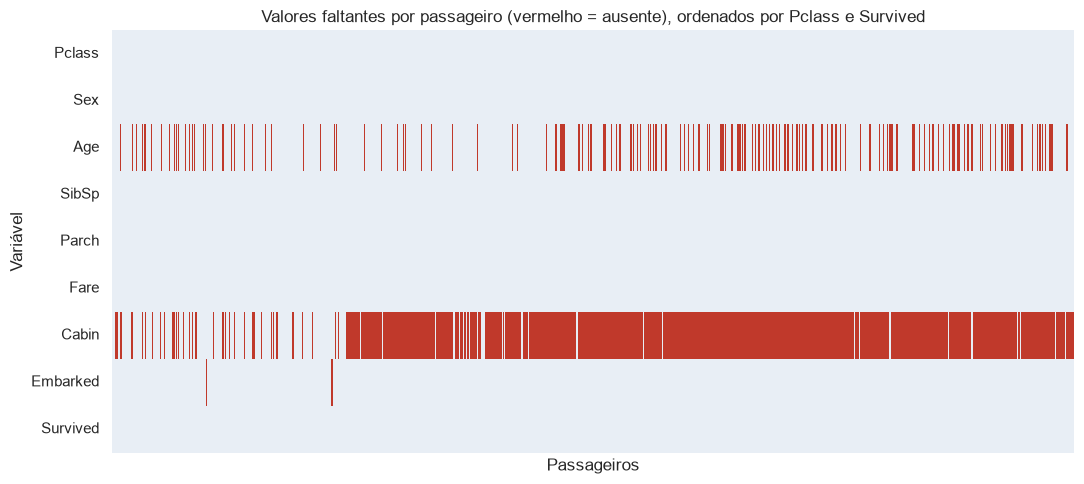

In [5]:
# [IA] Claude – mapa de valores faltantes (linhas ordenadas por classe)
cols = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Cabin", "Embarked", "Survived"]
ordenado = bruto.sort_values(["Pclass", "Survived"])[cols]
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(ordenado.isna().T, cbar=False, cmap=["#e8eef5", "#c0392b"], ax=ax)
ax.set_title("Valores faltantes por passageiro (vermelho = ausente), ordenados por Pclass e Survived")
ax.set_xlabel("Passageiros")
ax.set_ylabel("Variável")
ax.set_xticks([])
fig.tight_layout()
salvar(fig, "faltantes_mapa.png")
plt.show()

In [6]:
# [IA] Claude – taxa de ausência de Age e Cabin por grupo
grupos = ["Pclass", "Sex", "Survived", "Embarked", "Title"]
linhas = []
for g in grupos:
    t = df.groupby(g, dropna=False).agg(
        n=("PassengerId", "size"),
        pct_Age_ausente=("Age_missing", "mean"),
        pct_Cabin_ausente=("Cabin_known", lambda s: 1 - s.mean()),
    )
    t.index = [f"{g} = {i}" for i in t.index]
    linhas.append(t)
taxas = pd.concat(linhas)
taxas[["pct_Age_ausente", "pct_Cabin_ausente"]] *= 100
taxas.round(1)

,n,pct_Age_ausente,pct_Cabin_ausente
Pclass = 1,216,13.9,18.5
Pclass = 2,184,6.0,91.3
Pclass = 3,491,27.7,97.6
Sex = female,314,16.9,69.1
Sex = male,577,21.5,81.5
Survived = 0,549,22.8,87.6
Survived = 1,342,15.2,60.2
Embarked = C,168,22.6,58.9
Embarked = Q,77,63.6,94.8
Embarked = S,644,14.0,80.0


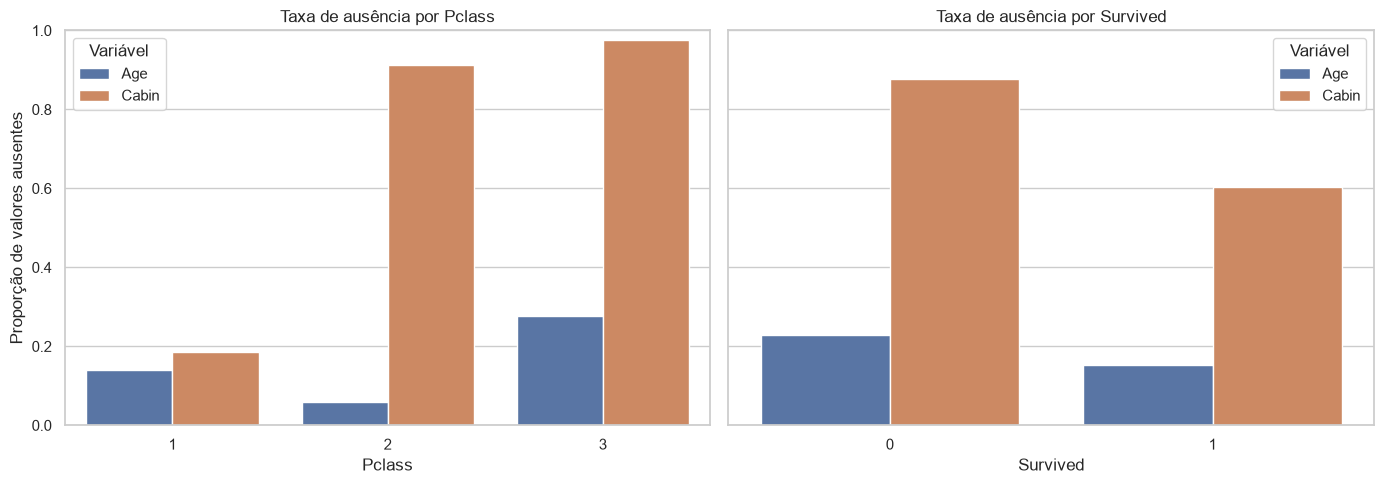

In [7]:
# [IA] Claude – gráfico da taxa de ausência por classe e por sobrevivência
plot_df = (
    df.assign(Cabin_ausente=1 - df["Cabin_known"])
    .melt(id_vars=["Pclass", "Survived"], value_vars=["Age_missing", "Cabin_ausente"],
          var_name="variavel", value_name="ausente")
    .replace({"variavel": {"Age_missing": "Age", "Cabin_ausente": "Cabin"}})
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, g in zip(axes, ["Pclass", "Survived"]):
    sns.barplot(data=plot_df, x=g, y="ausente", hue="variavel", errorbar=None, ax=ax)
    ax.set_title(f"Taxa de ausência por {g}")
    ax.set_xlabel(g)
    ax.set_ylabel("Proporção de valores ausentes")
    ax.set_ylim(0, 1)
    ax.legend(title="Variável")
fig.tight_layout()
salvar(fig, "faltantes_por_grupo.png")
plt.show()

In [8]:
# [IA] Claude – comparação das variáveis observadas entre quem tem e quem não tem Age
comp = df.groupby("Age_missing").agg(
    n=("PassengerId", "size"),
    taxa_sobrevivencia=("Survived", "mean"),
    fare_mediana=("Fare", "median"),
    pct_3a_classe=("Pclass", lambda s: (s == 3).mean()),
    pct_masculino=("Sex", lambda s: (s == "male").mean()),
)
comp.index = comp.index.map({0: "Age presente", 1: "Age ausente"})
comp

,n,taxa_sobrevivencia,fare_mediana,pct_3a_classe,pct_masculino
Age_missing,,,,,
Age presente,714,0.406,15.742,0.497,0.634
Age ausente,177,0.294,8.050,0.768,0.701


In [9]:
# [IA] Claude – passageiros sem Embarked
bruto[bruto["Embarked"].isna()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


> ✍️ **Análise do grupo:** _(preencher)_

_Qual o mecanismo de ausência de Age, Cabin e Embarked? Que evidências sustentam isso?_

### 2.1 Opções de tratamento de `Age`

Nenhuma linha é removida. Comparação de três opções de imputação (todas guardam `Age_missing` = 1 para os imputados):

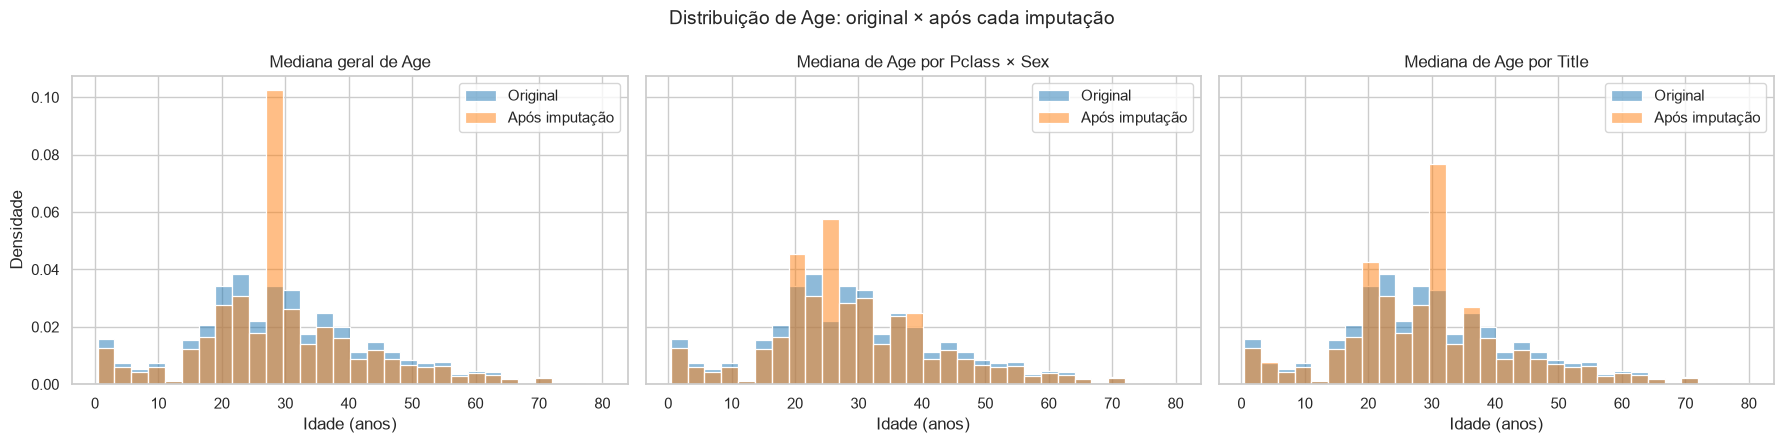

,count,mean,std,min,25%,50%,75%,max
original (sem faltantes),714.0,29.699,14.526,0.42,20.125,28.0,38.0,80.0
Mediana geral de Age,891.0,29.362,13.020,0.42,22.000,28.0,35.0,80.0
Mediana de Age por Pclass × Sex,891.0,29.112,13.304,0.42,21.500,26.0,36.0,80.0
Mediana de Age por Title,891.0,29.392,13.268,0.42,21.000,30.0,35.0,80.0


In [10]:
# [IA] Claude – comparação das opções de imputação de Age
fig, axes = plt.subplots(1, len(dd.METODOS_AGE), figsize=(18, 4.5), sharey=True)
resumo = {"original (sem faltantes)": df["Age"].describe()}
for ax, (metodo, nome) in zip(axes, dd.METODOS_AGE.items()):
    imputada = dd.imputar_age(df, metodo)
    resumo[nome] = imputada.describe()
    sns.histplot(df["Age"].dropna(), bins=30, stat="density", color="tab:blue", alpha=0.5,
                 label="Original", ax=ax)
    sns.histplot(imputada, bins=30, stat="density", color="tab:orange", alpha=0.5,
                 label="Após imputação", ax=ax)
    ax.set_title(nome)
    ax.set_xlabel("Idade (anos)")
    ax.set_ylabel("Densidade")
    ax.legend()
fig.suptitle("Distribuição de Age: original × após cada imputação", fontsize=14)
fig.tight_layout()
salvar(fig, "imputacao_age_opcoes.png")
plt.show()
pd.DataFrame(resumo).T

In [11]:
# [IA] Claude – mediana de Age usada por cada grupo
display(df.groupby(["Pclass", "Sex"])["Age"].median().unstack().rename_axis(index="Pclass", columns="Sex"))
display(df.groupby("Title")["Age"].agg(["median", "count"]))

Sex,female,male
Pclass,,
1,35.0,40.0
2,28.0,30.0
3,21.5,25.0


,median,count
Title,,
Master,3.5,36
Miss,21.0,149
Mr,30.0,398
Mrs,35.0,109
Raro,48.5,22


### 2.2 Tratamento adotado

**O grupo escolhe** o método em `METODO_AGE` (opções: `mediana_global`, `mediana_classe_sexo`, `mediana_titulo`)
e o tratamento de `Embarked` (`moda` ou `desconhecido`). `Cabin` não é imputada: vira `Deck = "Desconhecido"`.

O resultado é salvo em `data/parte_especifica/titanic_tratado.csv`, que é o arquivo lido pelo dashboard.

In [12]:
METODO_AGE = "mediana_titulo"   # o grupo deve confirmar ou trocar e justificar no relatório
EMBARKED = "moda"               # "moda" ou "desconhecido"

tratado = dd.tratar(bruto, METODO_AGE, EMBARKED)
tratado.to_csv(dd.CAMINHO_TRATADO, index=False)
print("Faltantes após tratamento:")
print(tratado[["Age", "Embarked", "Deck"]].isna().sum().to_string())
print(f"\nLinhas: {len(tratado)} (nenhuma removida)")

Faltantes após tratamento:
Age         0
Embarked    0
Deck        0

Linhas: 891 (nenhuma removida)


> ✍️ **Análise do grupo:** _(preencher)_

_Justificativa do tratamento escolhido._

## 3. Distribucional

A partir daqui usa-se o dataset tratado.

In [13]:
# [IA] Claude – estatísticas descritivas das quantitativas
quant = ["Age", "Fare", "SibSp", "Parch", "FamilySize", "TicketGroupSize"]
desc = tratado[quant].describe().T
desc["assimetria"] = tratado[quant].skew()
desc["curtose"] = tratado[quant].kurt()
desc

,count,mean,std,min,25%,50%,75%,max,assimetria,curtose
Age,891.0,29.392,13.268,0.42,21.00,30.000,35.0,80.000,0.437,0.775
Fare,891.0,32.204,49.693,0.00,7.91,14.454,31.0,512.329,4.787,33.398
SibSp,891.0,0.523,1.103,0.00,0.00,0.000,1.0,8.000,3.695,17.880
Parch,891.0,0.382,0.806,0.00,0.00,0.000,0.0,6.000,2.749,9.778
FamilySize,891.0,1.905,1.613,1.00,1.00,1.000,2.0,11.000,2.727,9.160
TicketGroupSize,891.0,1.788,1.361,1.00,1.00,1.000,2.0,7.000,2.221,4.777


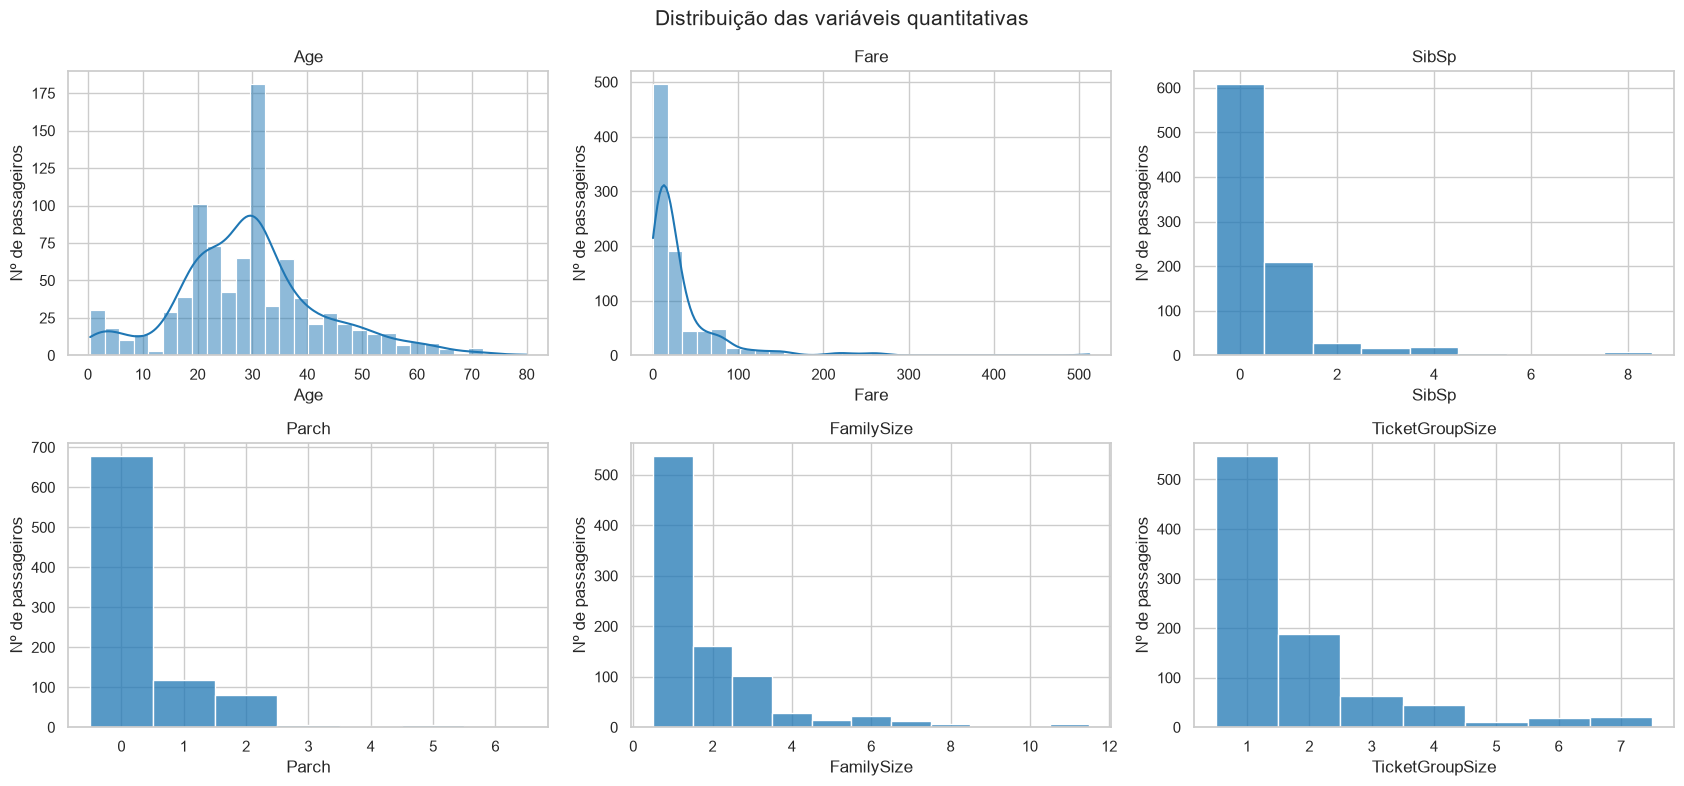

In [14]:
# [IA] Claude – histogramas das quantitativas
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, col in zip(axes.flat, quant):
    discreta = tratado[col].nunique() < 15
    sns.histplot(tratado[col], ax=ax, color="tab:blue", discrete=discreta,
                 bins="auto" if discreta else 30, kde=not discreta)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Nº de passageiros")
fig.suptitle("Distribuição das variáveis quantitativas", fontsize=15)
fig.tight_layout()
salvar(fig, "dist_quantitativas.png")
plt.show()

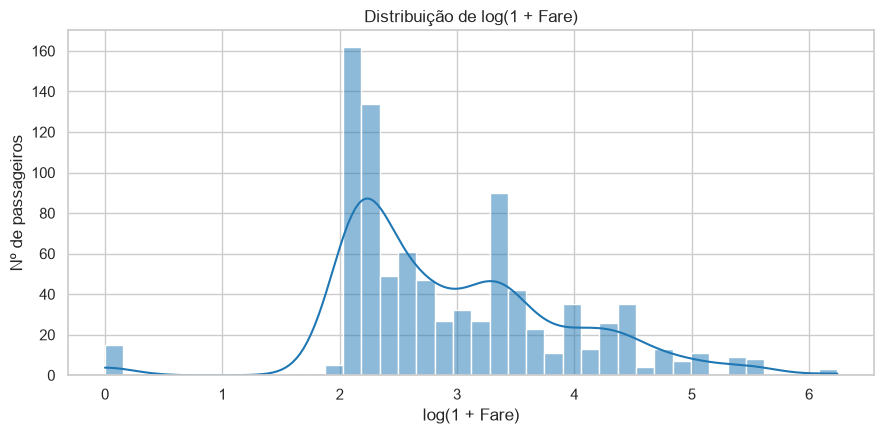

In [15]:
# [IA] Claude – Fare em escala logarítmica (distribuição muito assimétrica)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(np.log1p(tratado["Fare"]), bins=40, kde=True, ax=ax, color="tab:blue")
ax.set_title("Distribuição de log(1 + Fare)")
ax.set_xlabel("log(1 + Fare)")
ax.set_ylabel("Nº de passageiros")
fig.tight_layout()
salvar(fig, "dist_fare_log.png")
plt.show()

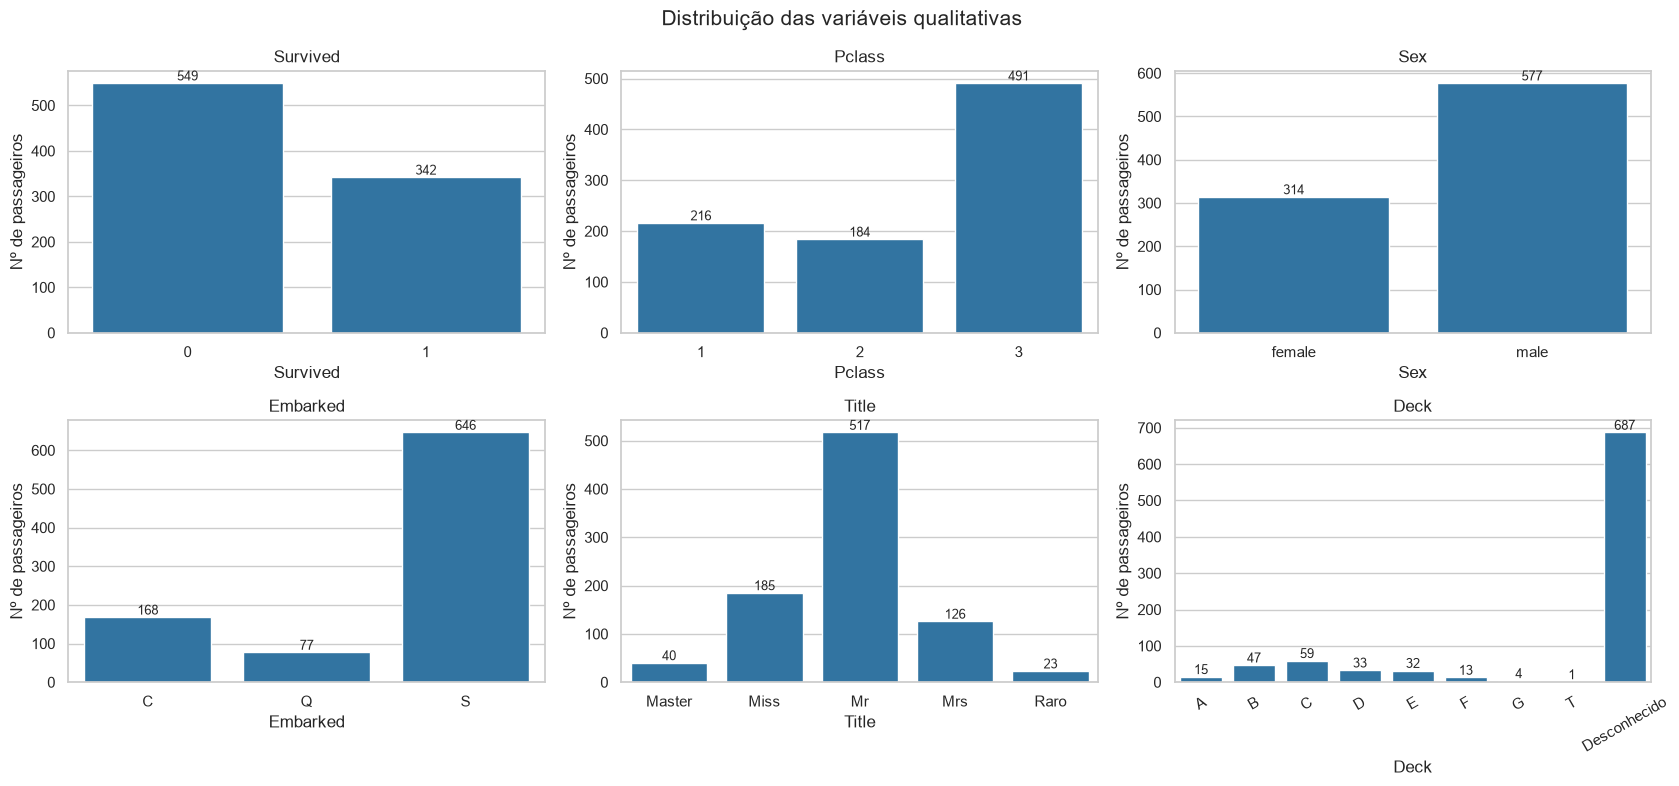

In [16]:
# [IA] Claude – frequência das qualitativas
quali = ["Survived", "Pclass", "Sex", "Embarked", "Title", "Deck"]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, col in zip(axes.flat, quali):
    ordem = sorted(tratado[col].unique(), key=lambda x: (x == "Desconhecido", str(x)))
    if col == "Deck":
        ax.tick_params(axis="x", rotation=30)
    sns.countplot(data=tratado, x=col, order=ordem, ax=ax, color="tab:blue")
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Nº de passageiros")
fig.suptitle("Distribuição das variáveis qualitativas", fontsize=15)
fig.tight_layout()
salvar(fig, "dist_qualitativas.png")
plt.show()

> ✍️ **Análise do grupo:** _(preencher)_

_Forma das distribuições, assimetria, equilíbrio da variável alvo._

## 4. Relacional

### 4.1 Taxa de sobrevivência por variável qualitativa

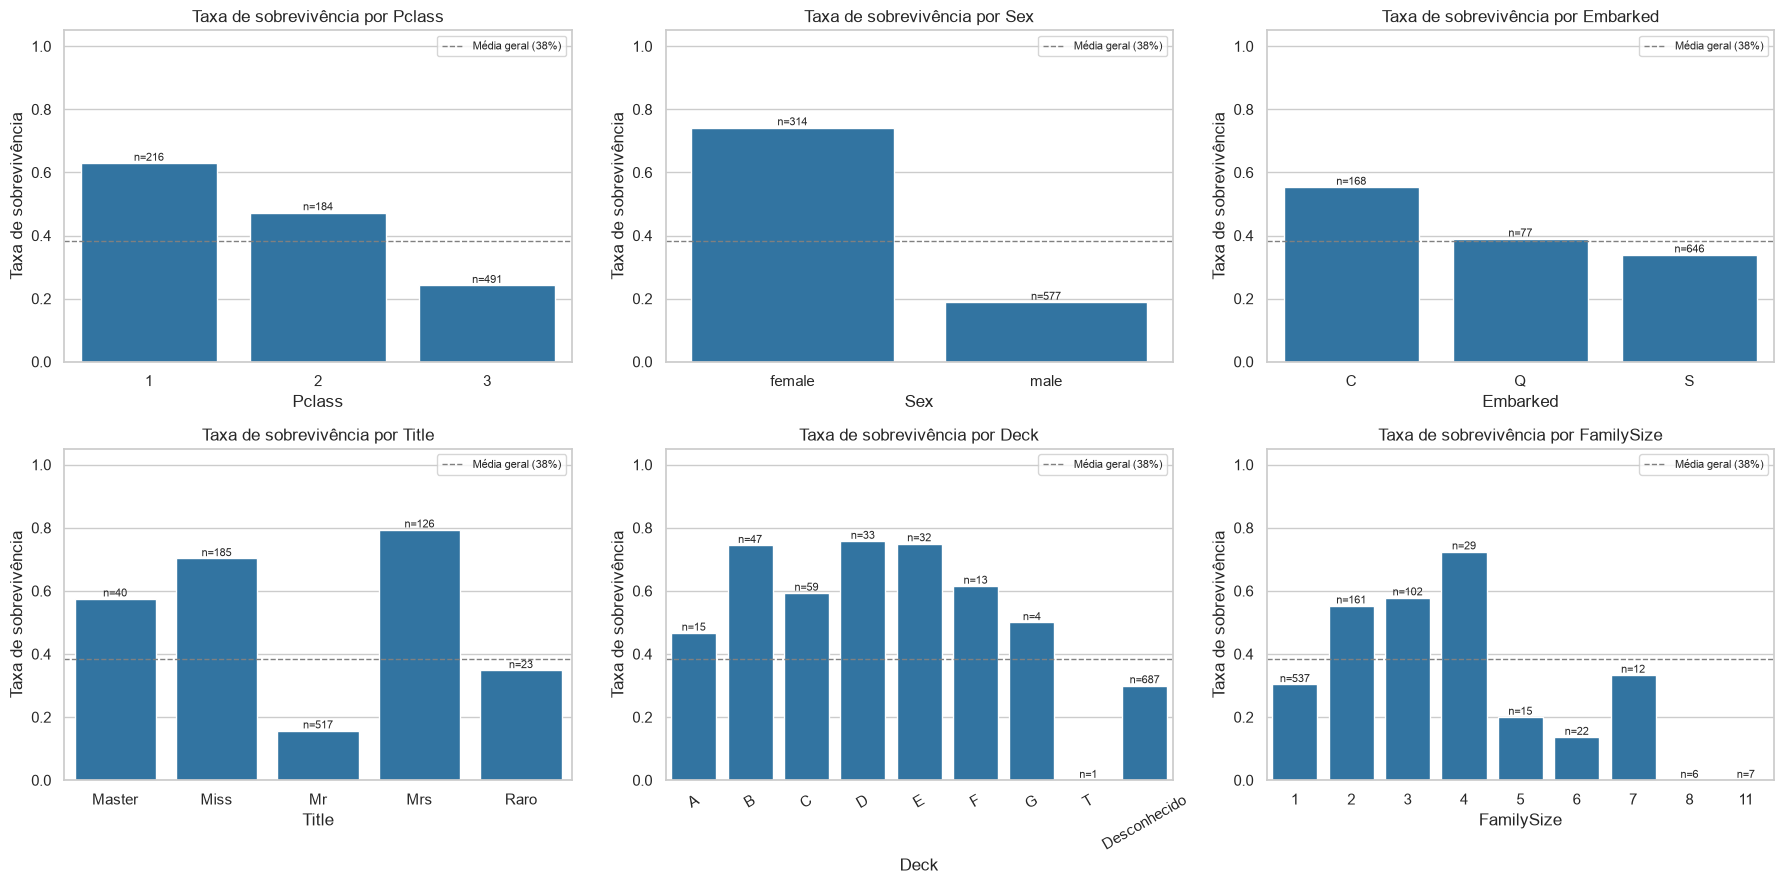

In [17]:
# [IA] Claude – taxa de sobrevivência por categoria (com nº de passageiros)
taxa_geral = tratado["Survived"].mean()
cats = ["Pclass", "Sex", "Embarked", "Title", "Deck", "FamilySize"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, cats):
    t = tratado.groupby(col)["Survived"].agg(["mean", "size"]).reset_index()
    t[col] = t[col].astype(str)
    if col == "Deck":  # "Desconhecido" por último
        t = t.sort_values(col, key=lambda s: s.eq("Desconhecido"), kind="stable")
        ax.tick_params(axis="x", rotation=30)
    sns.barplot(data=t, x=col, y="mean", ax=ax, color="tab:blue")
    for p, n in zip(ax.patches, t["size"]):
        ax.annotate(f"n={n}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=8)
    ax.axhline(taxa_geral, color="gray", linestyle="--", linewidth=1, label=f"Média geral ({taxa_geral:.0%})")
    ax.set_title(f"Taxa de sobrevivência por {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Taxa de sobrevivência")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
fig.tight_layout()
salvar(fig, "sobrevivencia_por_categoria.png")
plt.show()

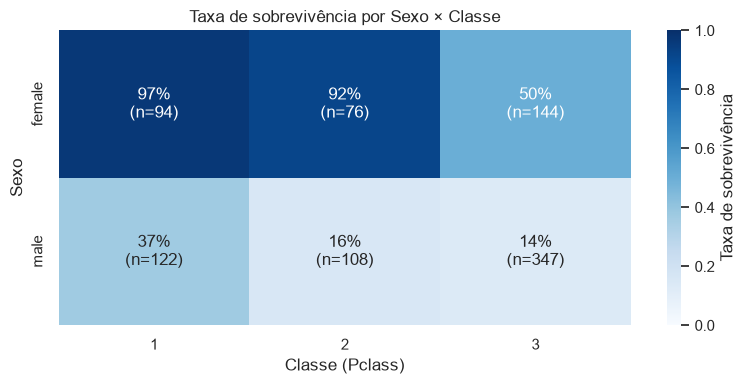

In [18]:
# [IA] Claude – sobrevivência por combinação Sex × Pclass
pivo = tratado.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean")
contagem = tratado.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="size")
rotulos = pivo.map(lambda v: f"{v:.0%}") + "\n(n=" + contagem.astype(str) + ")"
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(pivo, annot=rotulos, fmt="", cmap="Blues", vmin=0, vmax=1,
            cbar_kws={"label": "Taxa de sobrevivência"}, ax=ax)
ax.set_title("Taxa de sobrevivência por Sexo × Classe")
ax.set_xlabel("Classe (Pclass)")
ax.set_ylabel("Sexo")
fig.tight_layout()
salvar(fig, "sobrevivencia_sexo_classe.png")
plt.show()

### 4.2 Quantitativas × sobrevivência

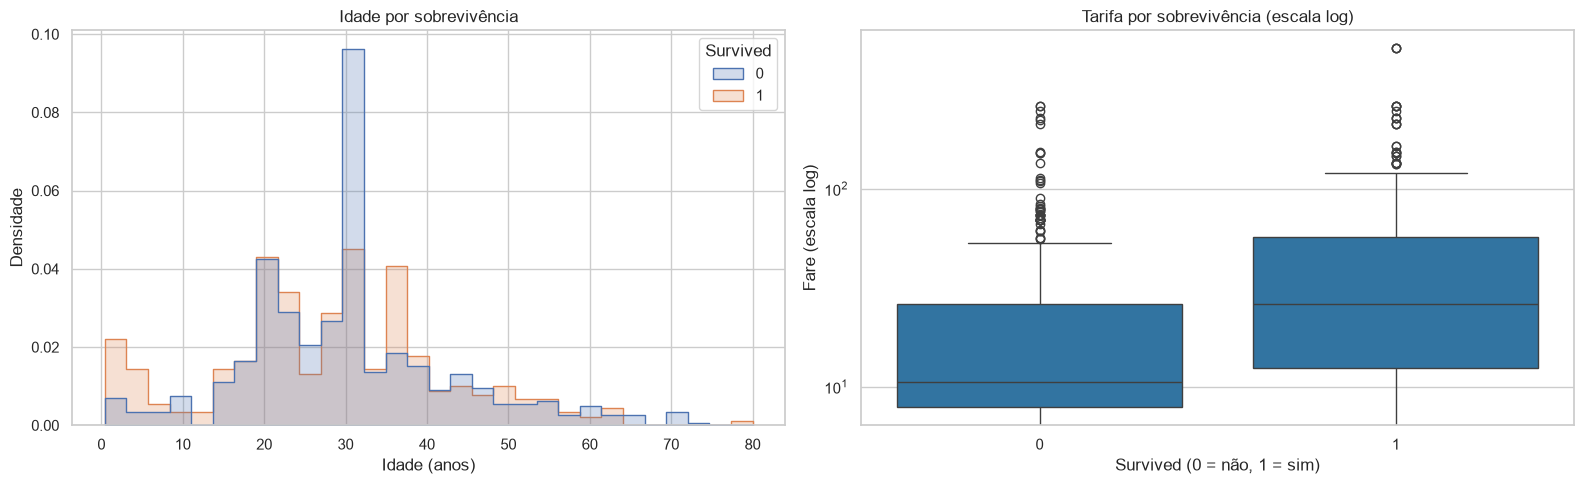

In [19]:
# [IA] Claude – distribuição de Age e Fare por sobrevivência
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(data=tratado, x="Age", hue="Survived", bins=30, element="step", stat="density",
             common_norm=False, ax=axes[0])
axes[0].set_title("Idade por sobrevivência")
axes[0].set_xlabel("Idade (anos)")
axes[0].set_ylabel("Densidade")
sns.boxplot(data=tratado, x="Survived", y="Fare", ax=axes[1], color="tab:blue")
axes[1].set_yscale("log")
axes[1].set_title("Tarifa por sobrevivência (escala log)")
axes[1].set_xlabel("Survived (0 = não, 1 = sim)")
axes[1].set_ylabel("Fare (escala log)")
fig.tight_layout()
salvar(fig, "age_fare_sobrevivencia.png")
plt.show()

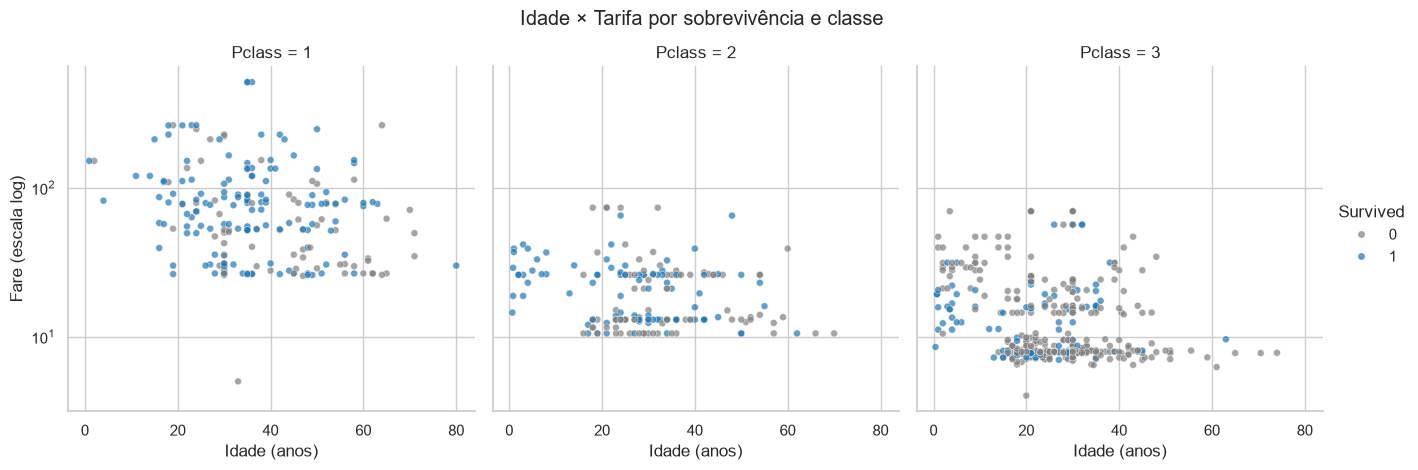

In [20]:
# [IA] Claude – idade × tarifa por sobrevivência, separado por classe
g = sns.relplot(data=tratado, x="Age", y="Fare", hue="Survived", col="Pclass",
                palette={0: "tab:gray", 1: "tab:blue"}, alpha=0.7, s=25, height=4.5)
g.set(yscale="log")
g.set_axis_labels("Idade (anos)", "Fare (escala log)")
g.set_titles("Pclass = {col_name}")
g.figure.suptitle("Idade × Tarifa por sobrevivência e classe", y=1.04)
g.savefig(OUT / "age_fare_classe.png", dpi=150, bbox_inches="tight")
plt.show()

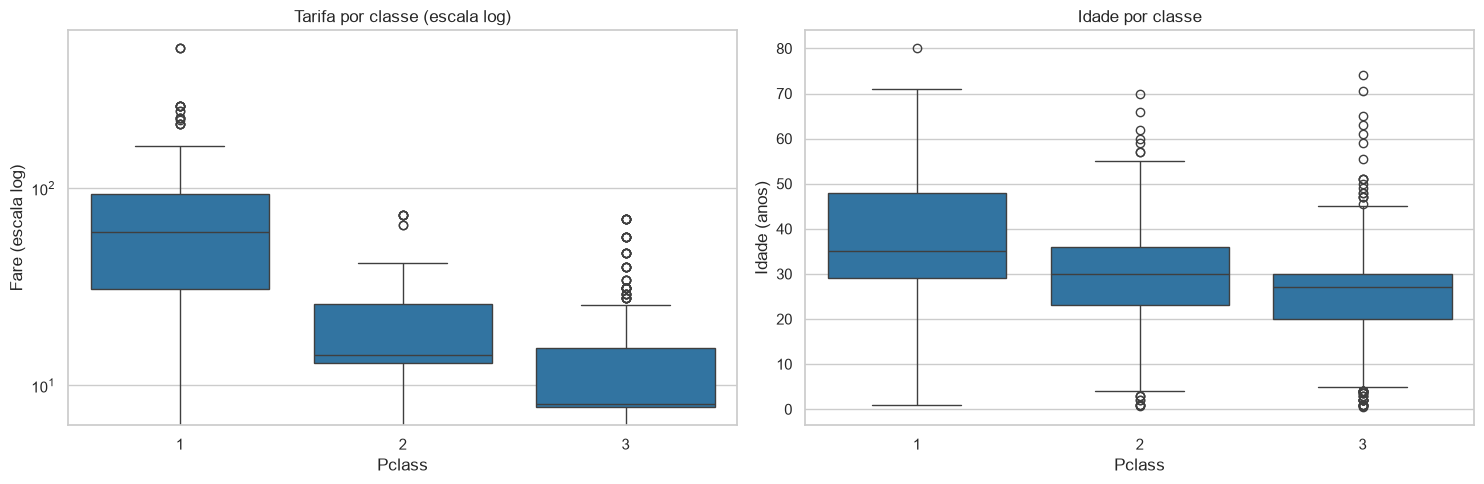

In [21]:
# [IA] Claude – boxplots de Fare e Age por classe
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=tratado, x="Pclass", y="Fare", ax=axes[0], color="tab:blue")
axes[0].set_yscale("log")
axes[0].set_title("Tarifa por classe (escala log)")
axes[0].set_xlabel("Pclass")
axes[0].set_ylabel("Fare (escala log)")
sns.boxplot(data=tratado, x="Pclass", y="Age", ax=axes[1], color="tab:blue")
axes[1].set_title("Idade por classe")
axes[1].set_xlabel("Pclass")
axes[1].set_ylabel("Idade (anos)")
fig.tight_layout()
salvar(fig, "fare_age_classe.png")
plt.show()

### 4.3 Matrizes de associação

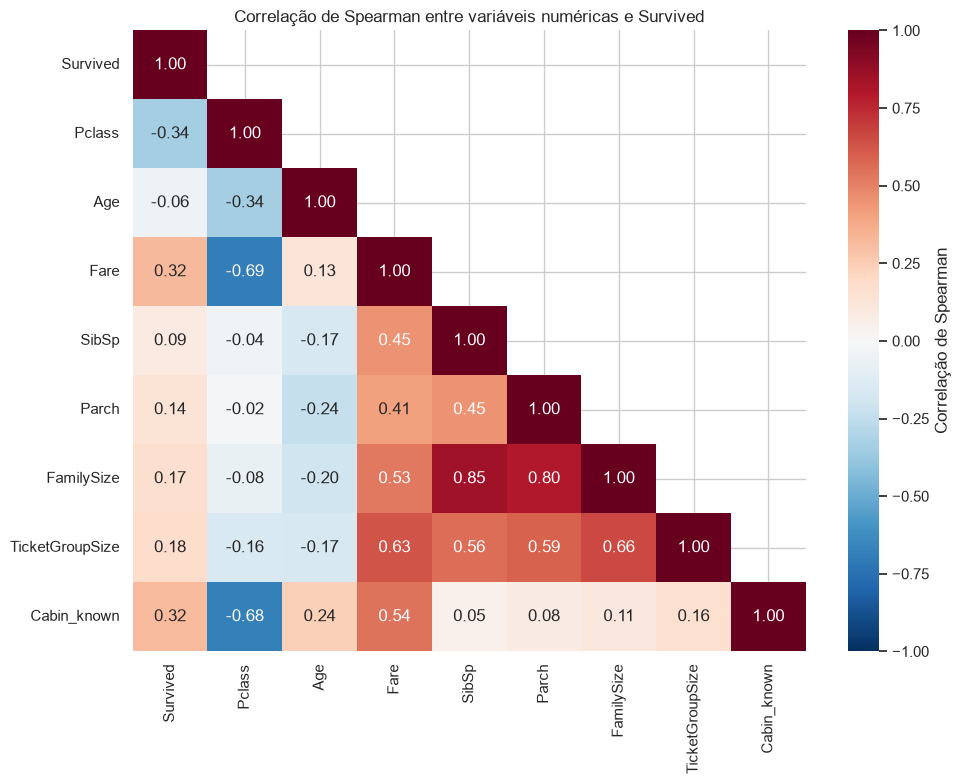

In [22]:
# [IA] Claude – correlação (Spearman) entre quantitativas e o alvo
num = ["Survived", "Pclass", "Age", "Fare", "SibSp", "Parch", "FamilySize", "TicketGroupSize", "Cabin_known"]
corr = tratado[num].corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            cbar_kws={"label": "Correlação de Spearman"}, ax=ax)
ax.set_title("Correlação de Spearman entre variáveis numéricas e Survived")
fig.tight_layout()
salvar(fig, "corr_spearman.png")
plt.show()

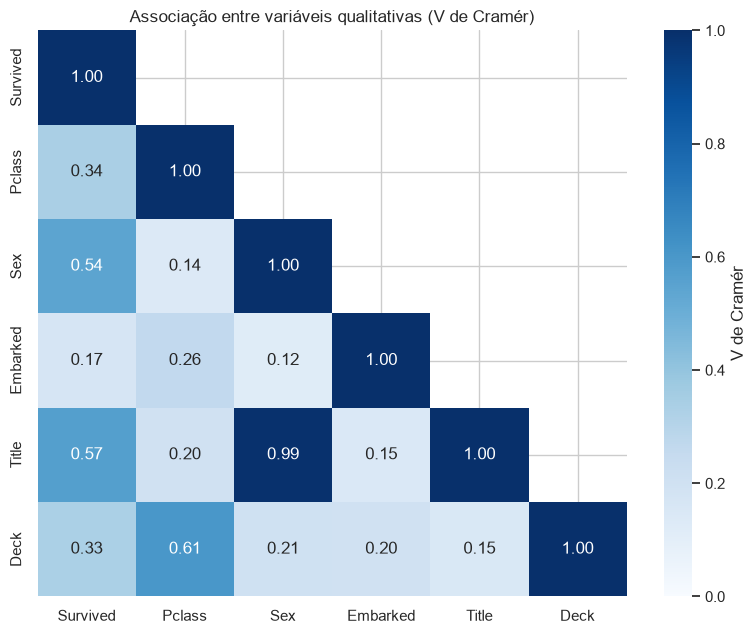

In [23]:
# [IA] Claude – V de Cramér entre qualitativas
qualis = ["Survived", "Pclass", "Sex", "Embarked", "Title", "Deck"]
v = pd.DataFrame(index=qualis, columns=qualis, dtype=float)
for a in qualis:
    for b in qualis:
        v.loc[a, b] = dd.cramers_v(tratado[a], tratado[b])
mascara = np.triu(np.ones_like(v, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(v, mask=mascara, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            cbar_kws={"label": "V de Cramér"}, ax=ax)
ax.set_title("Associação entre variáveis qualitativas (V de Cramér)")
fig.tight_layout()
salvar(fig, "cramers_v.png")
plt.show()

> ✍️ **Análise do grupo:** _(preencher)_

_Quais variáveis se relacionam com a sobrevivência? Há interações (ex.: entre sexo e classe)? Relação com a pergunta de pesquisa._

## 5. Outliers

Critério IQR (Q1 − 1,5·IQR, Q3 + 1,5·IQR) nas variáveis quantitativas.

In [24]:
# [IA] Claude – contagem de outliers por IQR
linhas = []
for col in ["Age", "Fare", "SibSp", "Parch", "FamilySize"]:
    li, ls = dd.limites_iqr(tratado[col])
    m = (tratado[col] < li) | (tratado[col] > ls)
    linhas.append({"variavel": col, "lim_inf": li, "lim_sup": ls, "n_outliers": m.sum(),
                   "% outliers": m.mean() * 100,
                   "taxa_sobrev_outliers": tratado.loc[m, "Survived"].mean()})
pd.DataFrame(linhas).set_index("variavel")

,lim_inf,lim_sup,n_outliers,% outliers,taxa_sobrev_outliers
variavel,,,,,
Age,0.000,56.000,35,3.928,0.286
Fare,-26.724,65.634,116,13.019,0.681
SibSp,-1.500,2.500,46,5.163,0.152
Parch,0.000,0.000,213,23.906,0.512
FamilySize,-0.500,3.500,91,10.213,0.341


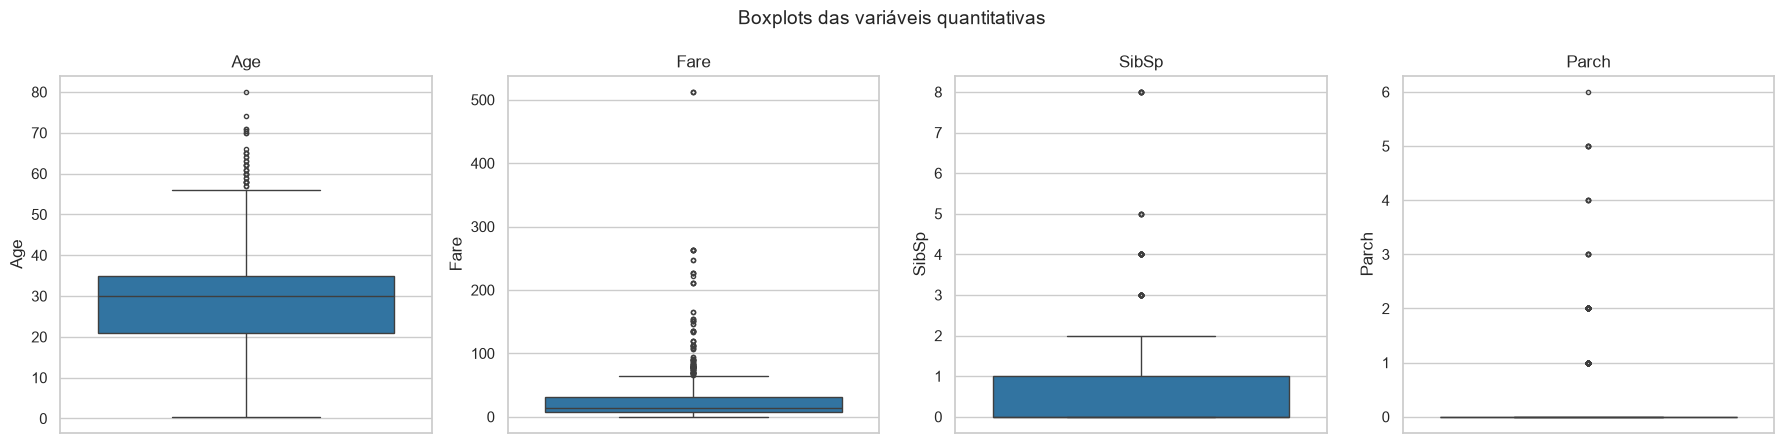

In [25]:
# [IA] Claude – boxplots das quantitativas com outliers
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, ["Age", "Fare", "SibSp", "Parch"]):
    sns.boxplot(y=tratado[col], ax=ax, color="tab:blue", fliersize=3)
    ax.set_title(col)
    ax.set_ylabel(col)
fig.suptitle("Boxplots das variáveis quantitativas", fontsize=14)
fig.tight_layout()
salvar(fig, "box_outliers.png")
plt.show()

In [26]:
# [IA] Claude – maiores tarifas e maiores famílias
cols = ["PassengerId", "Name", "Pclass", "Ticket", "Fare", "TicketGroupSize", "FamilySize", "Survived"]
display(tratado.nlargest(10, "Fare")[cols])
display(tratado.nlargest(10, "FamilySize")[cols])

,PassengerId,Name,Pclass,Ticket,Fare,TicketGroupSize,FamilySize,Survived
258,259,"Ward, Miss. Anna",1,PC 17755,512.329,3,1,1
679,680,"Cardeza, Mr. Thomas Drake Martinez",1,PC 17755,512.329,3,2,1
737,738,"Lesurer, Mr. Gustave J",1,PC 17755,512.329,3,1,1
27,28,"Fortune, Mr. Charles Alexander",1,19950,263.000,4,6,0
88,89,"Fortune, Miss. Mabel Helen",1,19950,263.000,4,6,1
341,342,"Fortune, Miss. Alice Elizabeth",1,19950,263.000,4,6,1
438,439,"Fortune, Mr. Mark",1,19950,263.000,4,6,0
311,312,"Ryerson, Miss. Emily Borie",1,PC 17608,262.375,2,5,1
742,743,"Ryerson, Miss. Susan Parker ""Suzette""",1,PC 17608,262.375,2,5,1
118,119,"Baxter, Mr. Quigg Edmond",1,PC 17558,247.521,2,2,0


,PassengerId,Name,Pclass,Ticket,Fare,TicketGroupSize,FamilySize,Survived
159,160,"Sage, Master. Thomas Henry",3,CA. 2343,69.55,7,11,0
180,181,"Sage, Miss. Constance Gladys",3,CA. 2343,69.55,7,11,0
201,202,"Sage, Mr. Frederick",3,CA. 2343,69.55,7,11,0
324,325,"Sage, Mr. George John Jr",3,CA. 2343,69.55,7,11,0
792,793,"Sage, Miss. Stella Anna",3,CA. 2343,69.55,7,11,0
846,847,"Sage, Mr. Douglas Bullen",3,CA. 2343,69.55,7,11,0
863,864,"Sage, Miss. Dorothy Edith ""Dolly""",3,CA. 2343,69.55,7,11,0
59,60,"Goodwin, Master. William Frederick",3,CA 2144,46.90,6,8,0
71,72,"Goodwin, Miss. Lillian Amy",3,CA 2144,46.90,6,8,0
386,387,"Goodwin, Master. Sidney Leonard",3,CA 2144,46.90,6,8,0


> ✍️ **Análise do grupo:** _(preencher)_

_Os outliers são erros ou valores legítimos? Serão mantidos, transformados ou excluídos, e por quê?_